# Preliminary Statistical Analysis of Language in Complaints with Descriptions
this notebook is meant to create some preliminary understanding of language frequently used in combination of our findings using LLMs and visualize our findings 


In [10]:
# Importing all necessary Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import CountVectorizer, ENGLISH_STOP_WORDS
import re

In [11]:
#import complaint data
df_complaints = pd.read_csv('../Joining Datasets/Data/complaints_combined_deduped.csv')
df_complaints.head()
df_complaints.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5645 entries, 0 to 5644
Data columns (total 16 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   ia_no                      5645 non-null   object 
 1   incident_type_x            5645 non-null   object 
 2   received_date_x            5645 non-null   object 
 3   occurred_date_x            4099 non-null   object 
 4   allegation_x               5358 non-null   object 
 5   finding_x                  5369 non-null   object 
 6   disposition_x              4103 non-null   object 
 7   label                      4652 non-null   object 
 8   narrative_x                5199 non-null   object 
 9   narrative_y                130 non-null    object 
 10  Off: Title/rank            993 non-null    object 
 11  Off: First name            993 non-null    object 
 12  Off: Last name             993 non-null    object 
 13  Off: Employee ID Number    993 non-null    float

In [12]:
#remove any rows with missing values in the 'Description' or 'Allegation' columns
df_complaints = df_complaints.dropna(subset=['narrative_x', 'allegation_x'])

In [13]:
# set all the text in the 'Description' and 'Allegation' columns to lowercase
df_complaints['narrative_x'] = df_complaints['narrative_x'].str.lower()
df_complaints['allegation_x'] = df_complaints['allegation_x'].str.lower()

In [14]:
df_complaints['allegation_x'].unique()
unique_allegations = df_complaints['allegation_x'].unique().tolist()

In [15]:
value_count_allegations = df_complaints["allegation_x"].value_counts()

In [16]:
print("Unique Allegations:", unique_allegations)

Unique Allegations: ['neg.duty/unreasonable judge', 'untruthfulness', 'use of force', 'neg.duty/unreasonable judge bias', 'conduct unbecoming', 'keaney use of force', 'keaney neg.duty/unreasonable judge', 'duggan use of force', 'emergey driving exercise of due caution', 'jr. neg.duty/unreasonable judge', 'respectful treatment', 'neg.duty/unreasonable judge (2 counts)', 'barrett use of force', 'dearden use of force', 'abuse of process', 'pointing firearms', 'conformance to laws', 'abuse of discretion', 'traffic enforcement', 'bias-free policing policy', 'conformance to laws filed retired with charges', 'conformance to laws filed resigned charges', 'evidence & found property', 'treatment', 'of process', 'self identification', 'tran respectful treatment', 'tran self identification', 'mccarthy use of force', 'mccarthy respectful treatment', 'identification', 'of force', 'of non-lethal force', 'patrol officer assigned to dept motor vehicle', 'respectful treatment bias', 'alcohol on duty', '

In [ ]:
# standardized label -> every raw variant (lowercase) that should collapse into it
GROUPS = {
 "Respectful Treatment": ["respectful treatment","respectful treatment (2 counts)","respectful treatment (3 counts)","respectful treatment bias","nrespectful treatment"],
 "Neglect of Duty / Unreasonable Judgment": ["neg.duty/unreasonable judge","neg.duty/unreasonable judge bias","neg.duty/unreasonable judge (2 counts)","neg.duty/unreasonable judge (2 counts","negduty/unreasonable judge","inegduty/unreasonable judge","unreasonable judgment bias","neglect of duty","negelct of duty","neglect of duty/unreasonable judgement","neglect of duty/unreasonable judgment (2 counts)","neglect of duty/unreasonable judgment (3 counts)","neglect of duty/unreasonable judgment (4 counts)","neglect of duty/unreasonable judgment (11 counts)"],
 "Use of Force": ["use of force","use of force (2 counts)"],
 "Investigation of Use of Force": ["investigation of use of force"],
 "Conduct Unbecoming": ["conduct unbecoming","conduct unbecoming (2 counts)","conduct unbecoming (3 counts)","conduct unbecoming (7 counts)","rule 102 sec. 3 - conduct","i"],
 "Conformance to Laws": ["conformance to laws","conformance to laws (2 counts)","conformance to laws (2counts)","conformance to laws (3 counts)","conformance to laws (11 counts)","conformance to laws (7 counts)","rule 102 sec. 35 - conformance to laws"],
 "Self Identification": ["self identification"],
 "Display of Identification": ["display of identification"],
 "BIAS-Free Policing Policy": ["bias-free policing policy"],
 "Abuse of Process": ["abuse of process"],
 "Abuse of Discretion": ["abuse of discretion"],
 "Police Service": ["police service"],
 "Manner of Recording Complaints": ["manner of recording complaints"],
 "Strip Search / Visual Body Cavity Search": ["strip search and or visual body cavity search"],
 "Search Suspect After Handcuffing": ["search suspect after handcuffing"],
 "Prisoner Handling / Booking Procedures": ["prisoners/booking procedures","booking procedures","handcuffs","prisoners","prisoners - cell inspection","prisoner inspection","prisoner - sickness or injury"],
 "Untruthfulness / Inaccurate Reporting": ["untruthfulness","untruthfulness (2 counts)","untruthfulness (3 counts)","untruthfulness in department report","untruthfulness in department reports (2 counts)","untruthfulness in department reports (3 counts)","untruthfulness in department reports (4 counts)","knowingly entering inaccurate false or improper information","department reports-truthfulness","department reports-inacurrate reporting"],
 "Accountability": ["accountability"],
 "Improper Statements": ["improper statements"],
 "Statement of Opinion": ["statement of opinion (6 counts)"],
 "Request for Interviews": ["request for interviews (6 counts)"],
 "Canon Seven": ["canon seven"],
 "Canon Eight": ["canon eight"],
 "CJIS / CORI Access": ["cjis access","cjis access (4 counts)","cori access","cori violation","cori procedures"],
 "Association with Criminals": ["association with criminals","association with criminals (2 counts)"],
 "Personal Business": ["personal business"],
 "Evidence & Found Property": ["evidence & found property"],
 "Safeguarding Non-Evidence Property": ["safeguarding non-evidence property"],
 "Handling & Disposition of Seized Money": ["handling & disposistion of seized money"],
 "Release of Property in Police Custody": ["release of property in police custody"],
 "Courts": ["courts"],
 "Courts - Failure to Appear When Summonsed": ["courts - failure to appear when summonsed (4 counts)"],
 "Alcohol on Duty": ["alcohol on duty","alcohol on duty (2 counts)","alcohol on duty (3 counts)"],
 "Alcohol in Police Facility": ["alcohol in police facility","alcohol in police facility (2 counts)","alcohol in police facility (3 counts)"],
 "Alcohol off Duty": ["alcohol off duty","alcohol off duty (5 counts)","rule 102 sec. 14 - use of alcohol off duty"],
 "Drug Testing / Controlled Substances": ["drug test","drug test (2 counts)","substance abuse policy","controlled substances","controlled substance notification (8 counts)","under the influence","prohibited conduct"],
 "Tobacco on Duty": ["tabacco on duty"],
 "Reporting for Duty": ["reporting for duty","reporting for duty (2 counts)","reporting for duty (3 counts)","officer unable to report for duty"],
 "Paid Details": ["paid details","paid details fitness for duty","detail cards","authorized details","paid detail authorized vendor","acceptance of details","acceptance of details (2 counts)","paid detail assignment"]
              + [f"paid detail assignment ({n} counts)" for n in (3,4,8,16,17,18,20,21,23,41,44,71,89,98,131)],
 "Directives / Orders": ["directives/orders","directives/orders (3 counts)","directives/orders (5 counts)","directives & orders (2 counts)","directives & orders (3 counts)"],
 "Failure to Notify Supervisor When Leaving Assigned Post": ["failure to notify supervisor when leaving their assigned post"],
 "P.O. Notifying Operations": ["p.o. notifying operations (3 counts)","p.o. notifying operations (9 counts)"],
 "Sleeping on Duty": ["sleeping on duty"],
 "Sick Leave": ["sick leave"],
 "Leaves of Absence": ["leaves of absence"],
 "Off Duty Employment w/out Permission": ["off duty employment w/out permission"],
 "Residency": ["residency"],
 "Change of Address Notification Violation": ["change of address notification violation"],
 "Residence and Telephone": ["residence and telephone"],
 "Uniform & Equipment": ["uniforms and equipment","uniform specifications","uniform & equipment-care & maintenance","uniform & equipment - shoes","uniform & equipment - trousers"],
 "Body-Worn Camera Policy": ["special order 16-023 section 2.5 bwc notice of recording","body worn camera policy - categorization","body worn policy - activation & incidents of use","bwc activation & incidents of use"],
 "Vehicle Operation / Accidents": ["emergency driving","emergency driving weather & enviornmental conditions","dept. motor vehicle accidents","department motor vehicle accidents notifications"],
 "Permissible Weapons & Ammunition": ["permissible weapons & ammunition"],
 "Reporting Firearms Discharge": ["reporting firearms dishcarge"],
 "Securing and Maintenance of Firearm": ["securing and maintenance of firearm"],
 "Failing to Submit Reports in Timely Manner": ["failing to submit reports in timely manner"],
 "Duty Supervisor": ["duty supervisor"],
 "Area Commanders": ["area commanders"],
 "Special Order 99-48 Dept E-Mail and Computer Use": ["special order 99-48 dept e-mail and computer use"],
 "Violations of Rules & Procedures": ["violations of rules & procedures"],
 "Failure to Be Knowledgeable & Informed": ["failure to be knowledgeable & informed"],
 "Mutual Protection": ["mutual protection"],
 "Information Dept. Members May Not Release": ["information dep.o. members may not release"],
 "Criminal Complaints": ["criminal complaints"],
 "Radio Procedures": ["radio procedures"],
 "F.I.O Reports": ["f.i.o reports"],
 "Completion of FIOE Report": ["completion of fioe report"],
 "Harassment Policy / Sexual Harassment": ["harassment policy","harassment policy - confidentiality","harassment policy - retaliation","harassment policy - retaliation (2 counts)","harassment policy - retaliation (3 counts)","sexual harassment - supervisor responsibilities","sexual harassment - unlawful conduct/harassment"],
 "Hostile Work Environment": ["hostile work environment","hostile work environment (6 counts)"],
 "Situations Involving Family / Domestic": ["situations involving family & frien","situations involving family members","domestic situations involving dep.o. employees"],
 "Situations Involving Off-Duty Boston P.O.s": ["situations involving off-duty boston p.o.s"],
}

# flip into the plain dictionary you apply to the column
allegation_map = {raw: clean for clean, raws in GROUPS.items() for raw in raws}

In [18]:
# flag bias-labeled rows BEFORE they get merged into their parent allegation
df_complaints["bias_label"] = df_complaints["allegation_x"].str.contains("bias", case=False, na=False)

key = (df_complaints["allegation_x"].astype(str).str.strip().str.lower()
         .str.replace(r"\s+", " ", regex=True))
df_complaints["allegation_clean"] = key.map(allegation_map)

In [19]:
df_complaints.head()

,ia_no,incident_type_x,received_date_x,occurred_date_x,allegation_x,finding_x,disposition_x,label,narrative_x,narrative_y,Off: Title/rank,Off: First name,Off: Last name,Off: Employee ID Number,Act: Action taken,Act: Days/hours suspended,bias_label,allegation_clean
0,IAD2011-0102,Citizen complaint,2/22/2011,2/22/2011,neg.duty/unreasonable judge,Exonerated,Exonerated,NO,complainant stated he was requested to move hi...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,Neglect of Duty / Unreasonable Judgment
1,IAD2011-0604,Citizen complaint,12/31/2011,4/18/2006,untruthfulness,Unfounded,Exonerated,NO,complainant would like to talk to someone conc...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,Untruthfulness / Inaccurate Reporting
2,IAD2011-0272,Citizen complaint,6/1/2011,NaN,use of force,Unfounded,Exonerated,NO,complainant walked into headquarters. complain...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,Use of Force
3,IAD2011-0458,Citizen complaint,9/29/2011,3/21/2008,neg.duty/unreasonable judge,Exonerated,Exonerated,NO,complainant [name] telephoned the offices of i...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,Neglect of Duty / Unreasonable Judgment
4,IAD2011-0020,Citizen complaint,1/13/2011,NaN,neg.duty/unreasonable judge,Exonerated,Exonerated,NO,i was exploring the copley shopping center on ...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,Neglect of Duty / Unreasonable Judgment


In [20]:
DOMAIN_STOP = {"officer","officers","po","police","boston","bpd","department","dept","alleged","allegedly",
               "said","says","told","stated","complainant","complaint","incident","rule","102","sec","section",
               "mr","ms","mrs","pm","am","street","st","ave","avenue", "car", "did", "like", "number"}
STOP = list(ENGLISH_STOP_WORDS | DOMAIN_STOP)

In [21]:
cv = CountVectorizer(ngram_range=(1, 2), stop_words=STOP, min_df=5, binary=True)
X = cv.fit_transform(df_complaints["narrative_x"])
vocab = np.array(cv.get_feature_names_out())

In [22]:
print(vocab)

['00' '00 00' '00 06' ... 'zero' 'zone' 'zone danger']


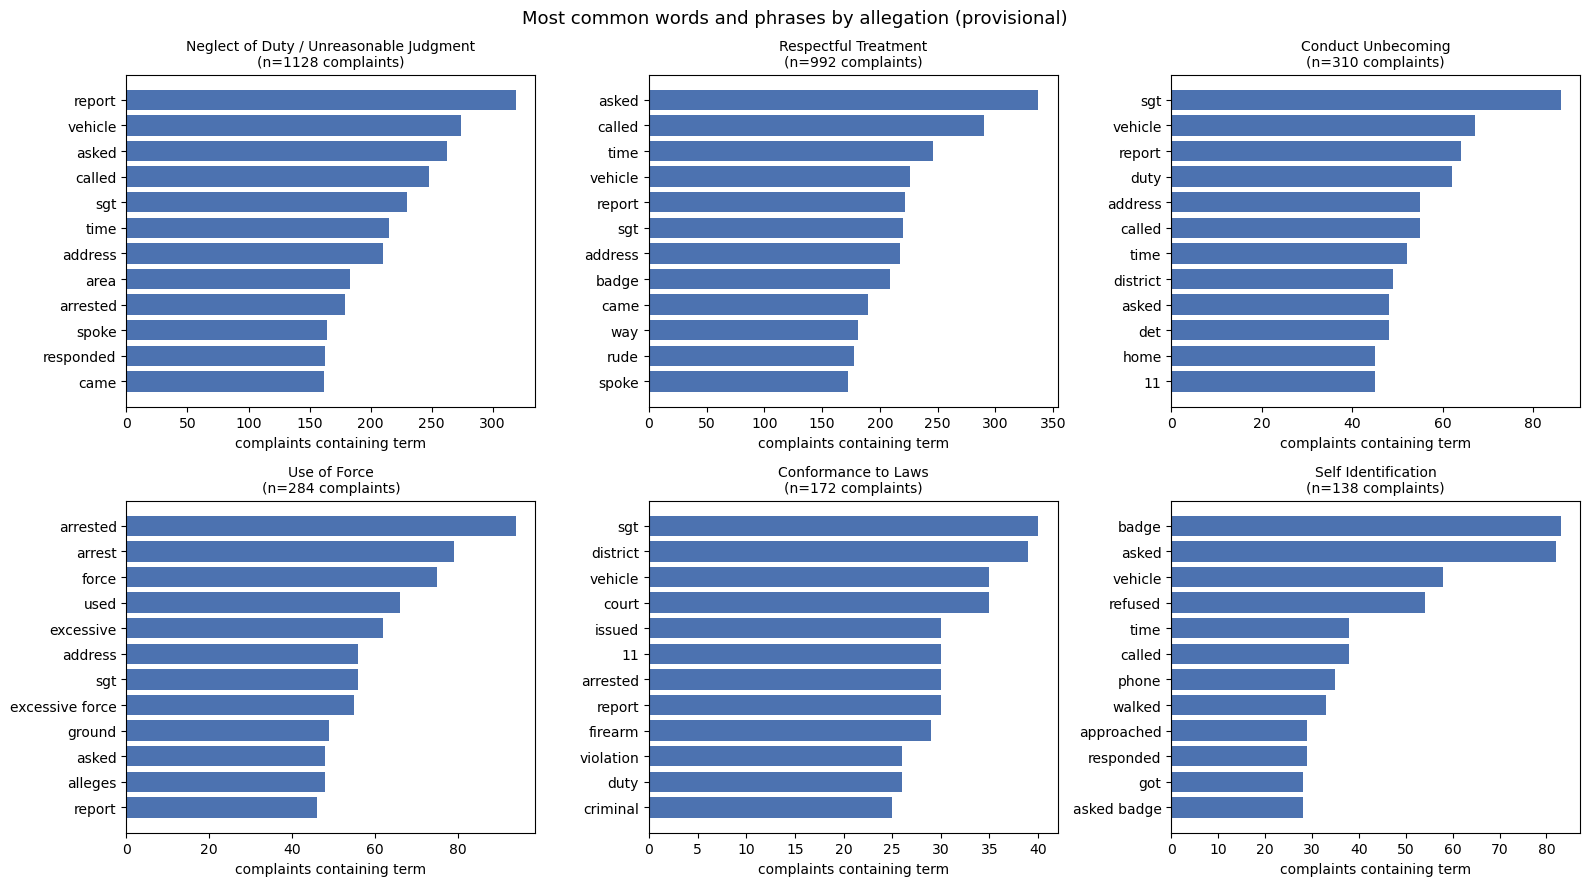

In [23]:
top_alleg = df_complaints["allegation_clean"].value_counts().head(6).index
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, a in zip(axes.ravel(), top_alleg):
    rows = (df_complaints["allegation_clean"] == a).values
    counts = np.asarray(X[rows].sum(0)).ravel()
    idx = counts.argsort()[::-1][:12]
    ax.barh(vocab[idx][::-1], counts[idx][::-1], color="#4C72B0")
    ax.set_title(f"{a}\n(n={rows.sum()} complaints)", fontsize=10)
    ax.set_xlabel("complaints containing term")
fig.suptitle("Most common words and phrases by allegation (provisional)", fontsize=13)
fig.tight_layout()

In [24]:
CATEGORY_COL = "allegation_clean"

# CHANGE THIS to the name of your complaint/narrative column.
TEXT_COL = "narrative_x"

# ============================================================
# DEFINE KEYWORD CONCEPTS
# ============================================================
# Each concept has a regular expression that includes variations.
# Matching is case-insensitive and uses word boundaries.
# Counts are calculated separately for every record.

KEYWORDS = {
    # Force and violence
    "Force": r"\bforce\b",
    "Excessive force": r"\bexcessive force\b",
    "Unnecessary force": r"\bunnecessary force\b",
    "Use of force": r"\buse of force\b",
    "Police brutality": r"\bpolice brutality\b",
    "Brutality": r"\bbrutalit(?:y|ies)\b",
    "Brutal": r"\bbrutal(?:ly)?\b",
    "Violence": r"\bviolence\b",
    "Violent": r"\bviolent(?:ly)?\b",
    "Deadly force": r"\bdeadly force\b",

    # Physical actions
    "Assault": r"\bassault(?:s|ed|ing)?\b",
    "Hit": r"\bhit(?:s|ting)?\b",
    "Punch": r"\bpunch(?:es|ed|ing)?\b",
    "Kick": r"\bkick(?:s|ed|ing)?\b",
    "Slap": r"\bslap(?:s|ped|ping)?\b",
    "Beat": r"\bbeat(?:s|en|ing)?\b",
    "Choke": r"\bchok(?:e|es|ed|ing)\b",
    "Push": r"\bpush(?:es|ed|ing)?\b",
    "Shove": r"\bshov(?:e|es|ed|ing)\b",
    "Grab": r"\bgrab(?:s|bed|bing)?\b",
    "Slam": r"\bslam(?:s|med|ming)?\b",
    "Throw": r"\bthrow(?:s|n|ing)?\b",
    "Drag": r"\bdrag(?:s|ged|ging)?\b",
    "Restrain": r"\brestrain(?:s|ed|ing)?\b|\brestraint\b",
    "Handcuff": r"\bhandcuff(?:s|ed|ing)?\b",
    "Twisted arm": r"\btwist(?:ed|s|ing)? arm\b",
    "Struck": r"\bstruck\b",
    "Got in my face": r"\bgot in my face\b",

    # Threats and interpersonal conduct
    "Threat": r"\bthreat(?:s|en|ened|ening)?\b",
    "Threatened to arrest": r"\bthreatened to arrest\b",
    "Harassment": r"\bharass(?:es|ed|ing)?\b|\bharassment\b",
    "Intimidation": r"\bintimidat(?:e|es|ed|ing|ion)\b",
    "Disrespect": r"\bdisrespect(?:s|ed|ful|fully)?\b",
    "Rude": r"\brude(?:ly|ness)?\b",
    "Unprofessional": r"\bunprofessional\b",
    "Attitude": r"\battitude\b",
    "Dismissive": r"\bdismissive(?:ly)?\b",
    "Condescending": r"\bcondescend(?:ing|ed|s)?\b|\bcondescension\b",
    "Did not listen": r"\bdid not listen\b|\bwould not listen\b",
    "Would not let me explain": r"\bwould not let me explain\b|\bwouldn't let me explain\b",
    "Made to wait": r"\bmade me wait\b|\bmade to wait\b",
    "Put on hold": r"\bput me on hold\b|\bput on hold\b",
    "Curt or abrupt": r"\bcurt\b|\babrupt\b",
    "Hung up on me": r"\bhung up on me\b",
    "Refused name or badge": r"\brefused to give (?:me )?(?:his |her |their )?(?:name|badge number)\b",
    "Yelled": r"\byell(?:s|ed|ing)?\b",
    "Screamed": r"\bscream(?:s|ed|ing)?\b",
    "Shouted": r"\bshout(?:s|ed|ing)?\b",
    "Insulted": r"\binsult(?:s|ed|ing)?\b",
    "Name-calling": r"\bname.?calling\b",
    "Mocked": r"\bmock(?:s|ed|ing|ery)?\b",
    "Taunted": r"\btaunt(?:s|ed|ing)?\b",
    "Confrontational": r"\bconfrontational\b",
    "Profanity": r"\b(?:fuck|fucking|bitch|asshole|bastard|shit|damn)\b",
    "Shut the fuck up": r"\bshut the fuck up\b",
    "Retaliation": r"\bretaliat(?:e|es|ed|ing|ion)\b",

    # Discrimination
    "Racism": r"\bracis(?:m|t|ts|tic)\b",
    "Racial": r"\bracial\b",
    "Profiling": r"\bprofil(?:e|ed|ing)\b|\bracial profiling\b",
    "Discrimination": r"\bdiscriminat(?:e|es|ed|ing|ion|ory)\b",
    "Racial slurs": r"\bracial slur(?:s)?\b",
    "Anti-LGBT slurs": r"\banti.?lgbt slur(?:s)?\b",
    "Disability or mental health remarks": (
        r"\bdisabilit(?:y|ies)\b|\bmental health\b"
    ),
    "Sexual insults": r"\bsuck his dick\b|\bsexual insult(?:s)?\b",
    "Search without consent": r"\bsearched without consent\b",
    "Entered without warrant": r"\bentered without (?:a )?warrant\b",

    # Injuries and potentially dangerous actions
    "Injury": r"\binjur(?:y|ies|ed|es|ing)\b",
    "Broken bone": r"\bbroken\b|\bbroke\b",
    "Fracture": r"\bfractur(?:e|es|ed|ing)\b",
    "Dislocation": r"\bdislocat(?:e|es|ed|ing|ion)\b",
    "Hospital": r"\bhospital(?:s|ized|isation|ization)?\b",
    "Surgery": r"\bsurger(?:y|ies)\b",
    "Knee on neck or back": r"\bknee on (?:my )?(?:neck|back)\b",
    "Pepper spray": r"\bpepper spray\b",
    "OC spray": r"\boc spray\b|\boleoresin capsicum\b",
    "Baton": r"\bbaton(?:s)?\b",
    "Gun pointed": r"\bgun (?:was )?pointed\b|\bpointed (?:a )?gun\b",
    "Denied medical attention": r"\bdenied (?:me )?medical attention\b",
    "Shot": r"\bshot\b|\bshoot(?:s|ing)?\b",
    "Firearm discharged": r"\bfirearm discharged\b",
    "Life-threatening": r"\blife.?threatening\b",
    "Unresponsive": r"\bunresponsive\b",
    "Death": r"\bdeath\b|\bdeaths\b|\bdied\b|\bdead\b",
    "Touched private parts": r"\btouched my private parts\b",
    "Strip search": r"\bstrip search(?:es|ed|ing)?\b",
    "Threatened to kill": r"\bthreatened to kill\b",
}



# COUNT OCCURRENCES FOR EACH RECORD
def count_matches(text, pattern):
    """Count non-overlapping matches of a concept in one record."""
    return len(re.findall(pattern, str(text), flags=re.IGNORECASE))


for concept, pattern in KEYWORDS.items():
    df_complaints[concept] = df_complaints[TEXT_COL].apply(
        lambda text: count_matches(text, pattern)
    )

# Binary version: 1 if a record mentions the concept at least once.
# Use this for co-occurrence and correlation analysis.
binary_df = df_complaints[list(KEYWORDS)].gt(0).astype(int)


# ============================================================
# SUMMARIZE BY CATEGORY IN COLUMN ALLEGATION_CLEAN
# ============================================================

# Total mentions of each concept within each category
category_counts = df_complaints.groupby(CATEGORY_COL)[list(KEYWORDS)].sum()

# Number of records in each category
category_sizes = df_complaints.groupby(CATEGORY_COL).size()

# Number of records in each category mentioning each concept
category_presence = binary_df.groupby(df_complaints[CATEGORY_COL]).sum()

# Percentage of records in each category mentioning each concept
category_prevalence = category_presence.div(
    category_sizes, axis=0
) * 100

In [ ]:
# Save each results table as a separate CSV file
"""category_counts.to_csv("total_mentions.csv")
category_presence.to_csv("records_mentioning.csv")
category_prevalence.to_csv("percent_of_records.csv")
df_complaints.to_csv("record_level_data.csv", index=False)

print("Saved all results as CSV files!")"""

Saved all results as CSV files!


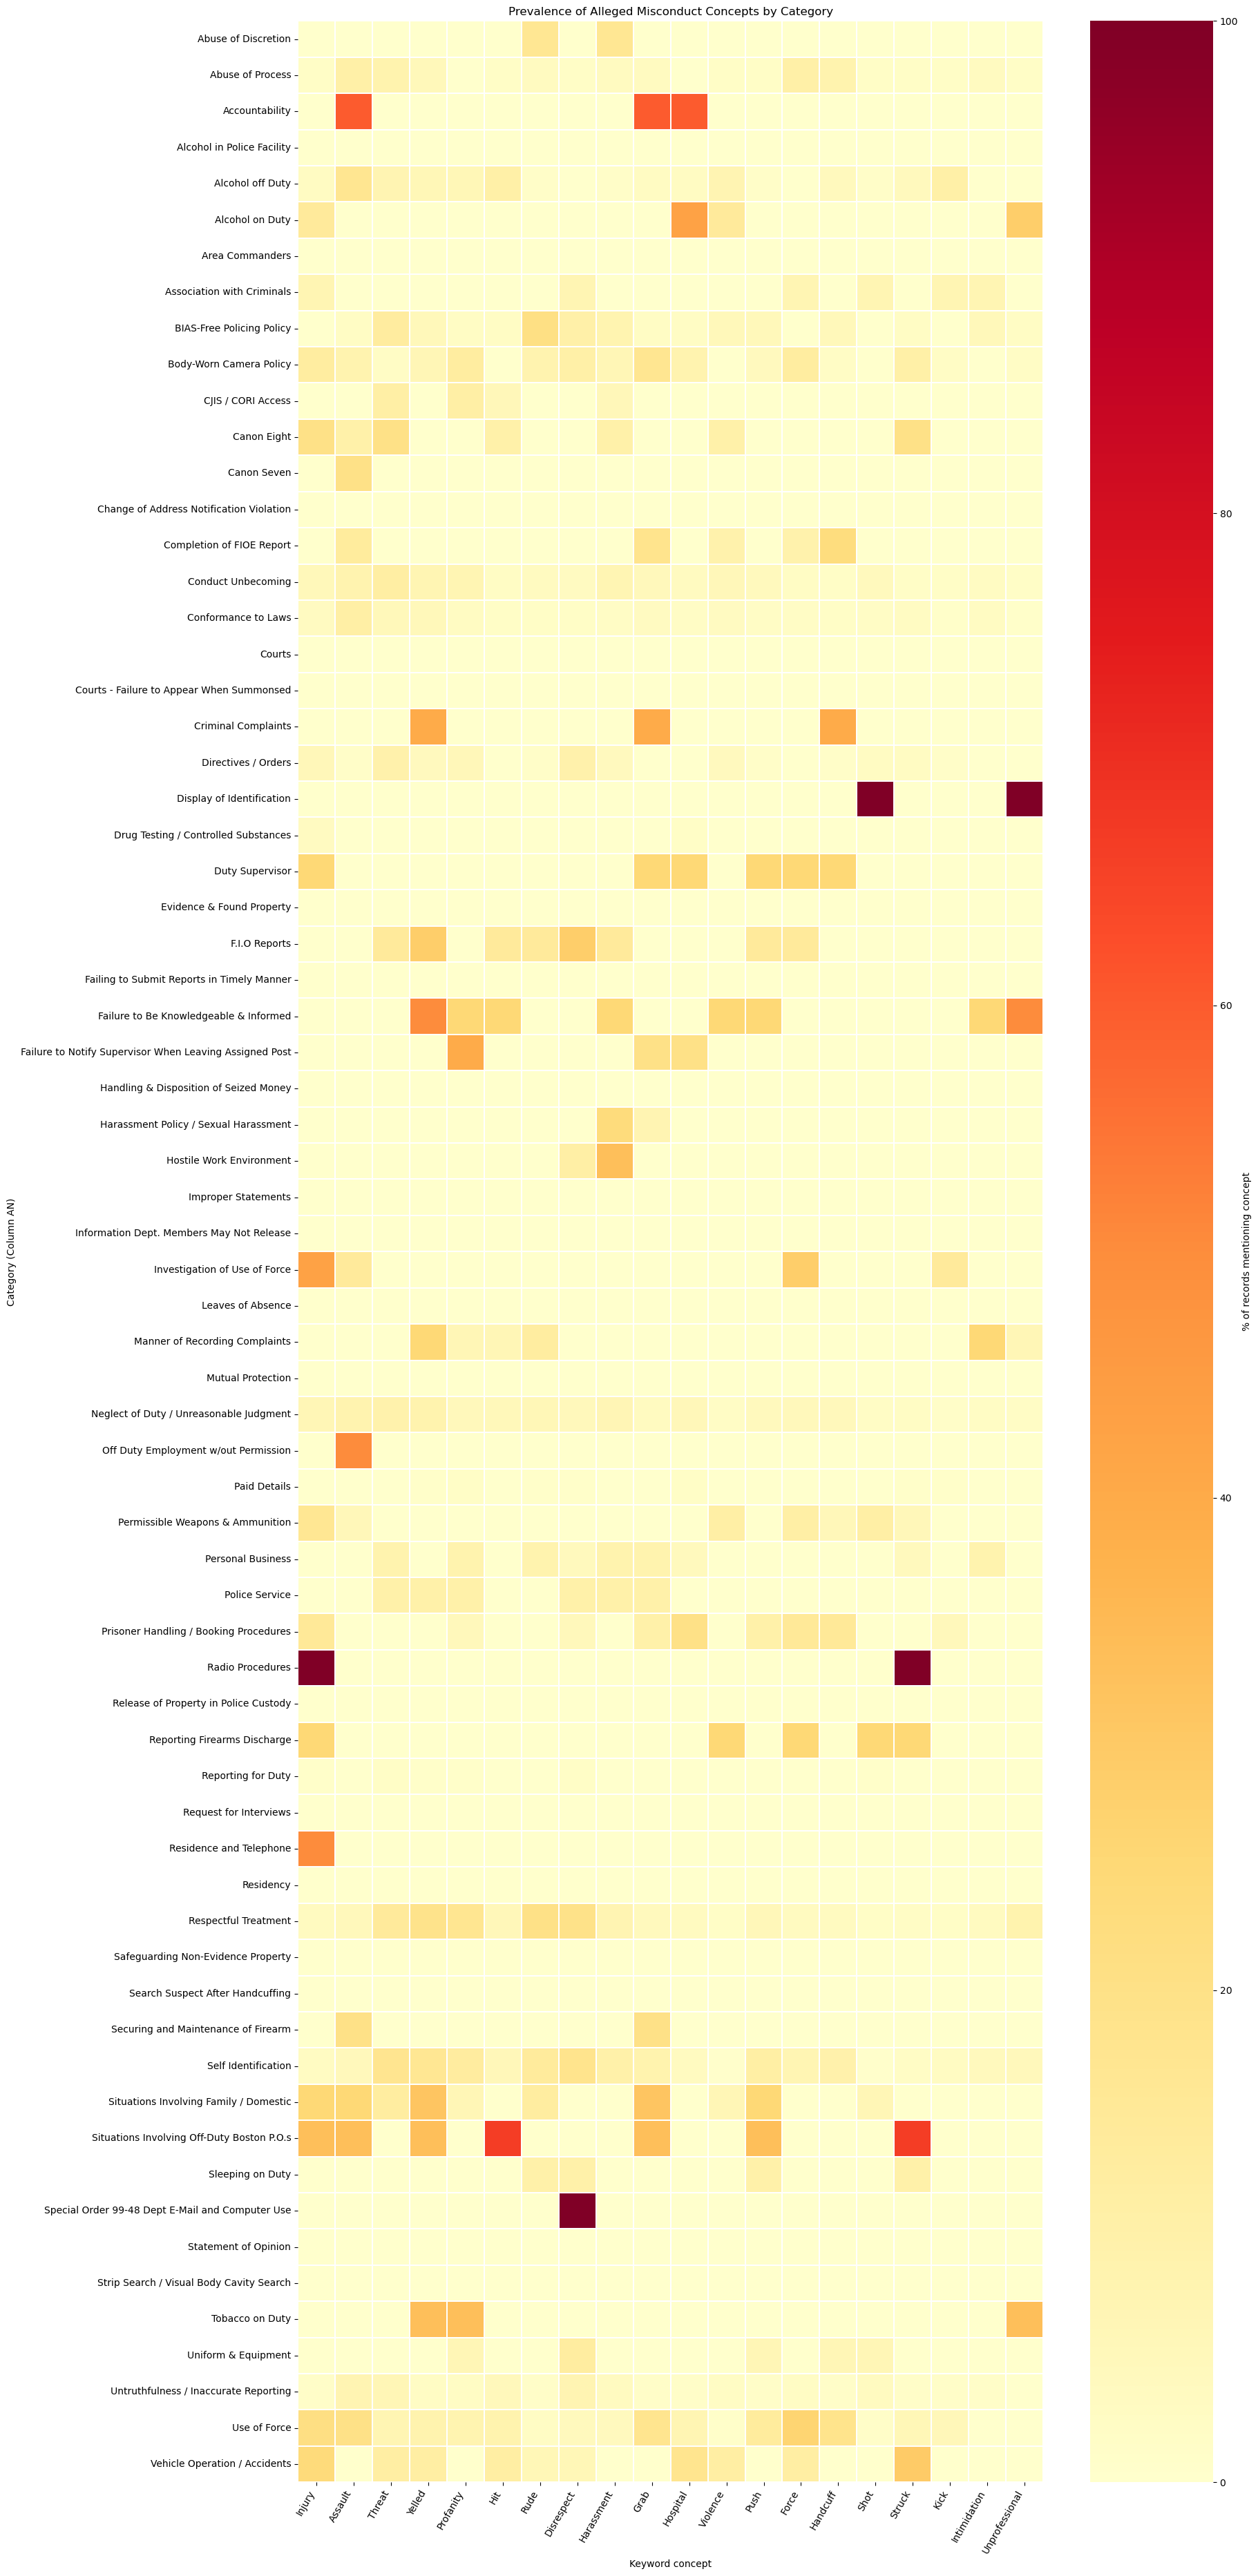

In [25]:
# ============================================================
# HEATMAP: KEYWORDS BY CATEGORY
# ============================================================

# Select the 20 most frequently mentioned concepts overall.
top_concepts = (
    df_complaints[list(KEYWORDS)].sum()
    .sort_values(ascending=False)
    .head(20)
    .index
)

plt.figure(figsize=(18, max(6, len(category_prevalence) * 0.55)))

sns.heatmap(
    category_prevalence[top_concepts],
    cmap="YlOrRd",
    linewidths=0.3,
    annot=False,
    cbar_kws={"label": "% of records mentioning concept"}
)

plt.title("Prevalence of Alleged Misconduct Concepts by Category")
plt.xlabel("Keyword concept")
plt.ylabel("Category (Column AN)")
plt.xticks(rotation=60, ha="right")
plt.tight_layout()
plt.show()

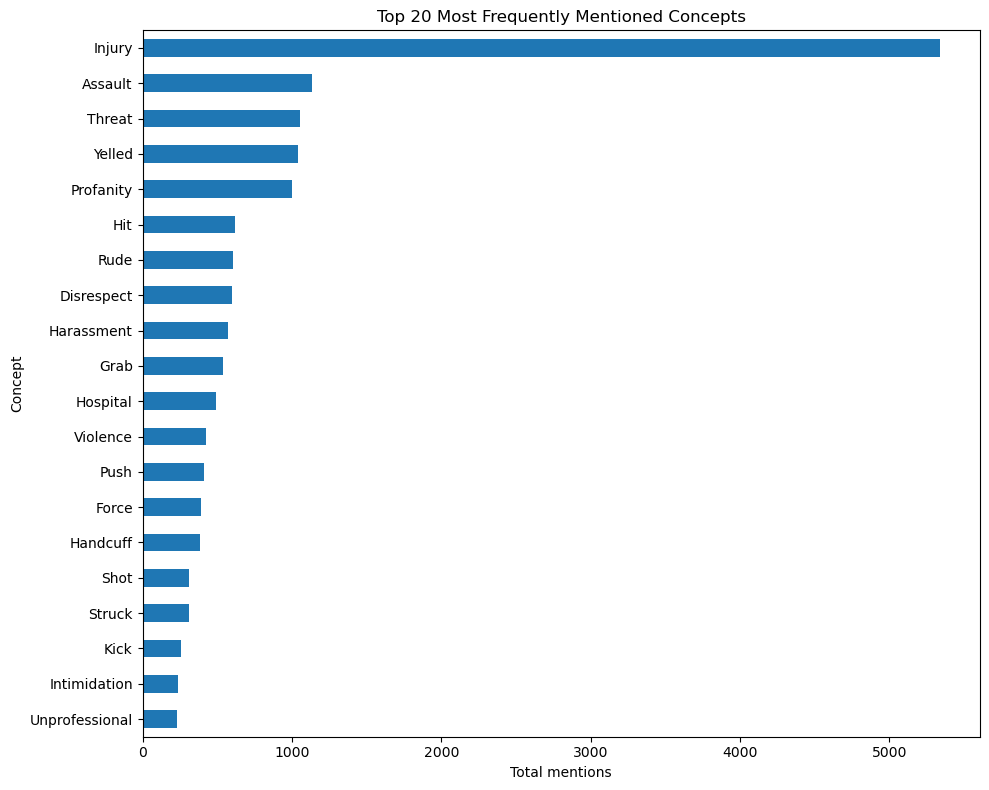

In [26]:
# ============================================================
# BAR CHART: MOST COMMON CONCEPTS OVERALL
# ============================================================

overall_mentions = df_complaints[list(KEYWORDS)].sum().sort_values(
    ascending=True
)

top_20 = overall_mentions.tail(20)

plt.figure(figsize=(10, 8))
top_20.plot(kind="barh")

plt.title("Top 20 Most Frequently Mentioned Concepts")
plt.xlabel("Total mentions")
plt.ylabel("Concept")
plt.tight_layout()
plt.show()


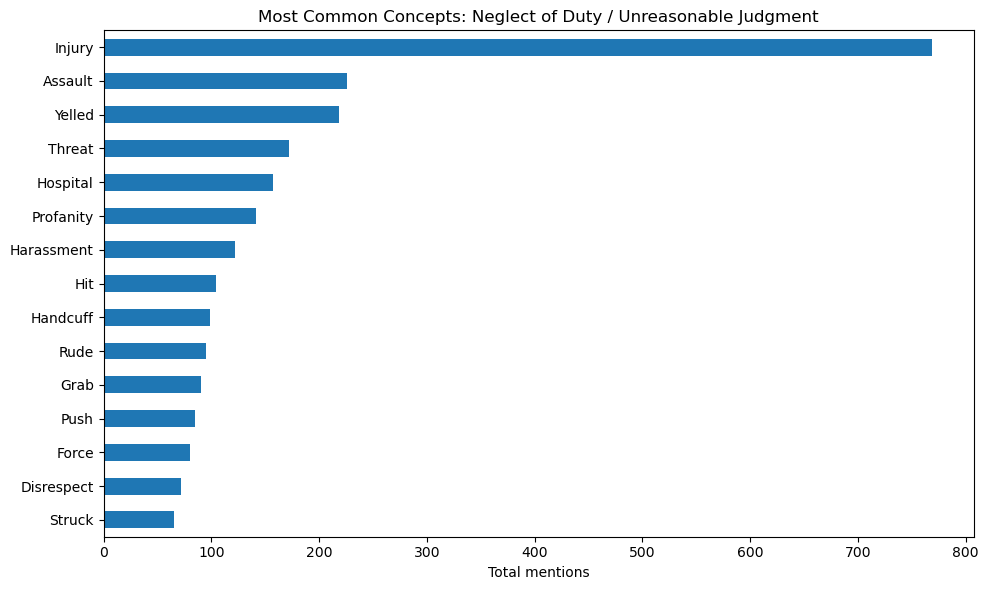

In [27]:
# ============================================================
# COMPARE CONCEPTS WITHIN ONE CATEGORY
# ============================================================

# Change this to a category value that exists in column ALLEGATION_CLEAN.
selected_category = df_complaints[CATEGORY_COL].value_counts().index[0]

category_data = df_complaints[df_complaints[CATEGORY_COL] == selected_category]

category_mentions = (
    category_data[list(KEYWORDS)]
    .sum()
    .sort_values(ascending=False)
    .head(15)
    .sort_values()
)

plt.figure(figsize=(10, 6))
category_mentions.plot(kind="barh")

plt.title(f"Most Common Concepts: {selected_category}")
plt.xlabel("Total mentions")
plt.tight_layout()
plt.show()



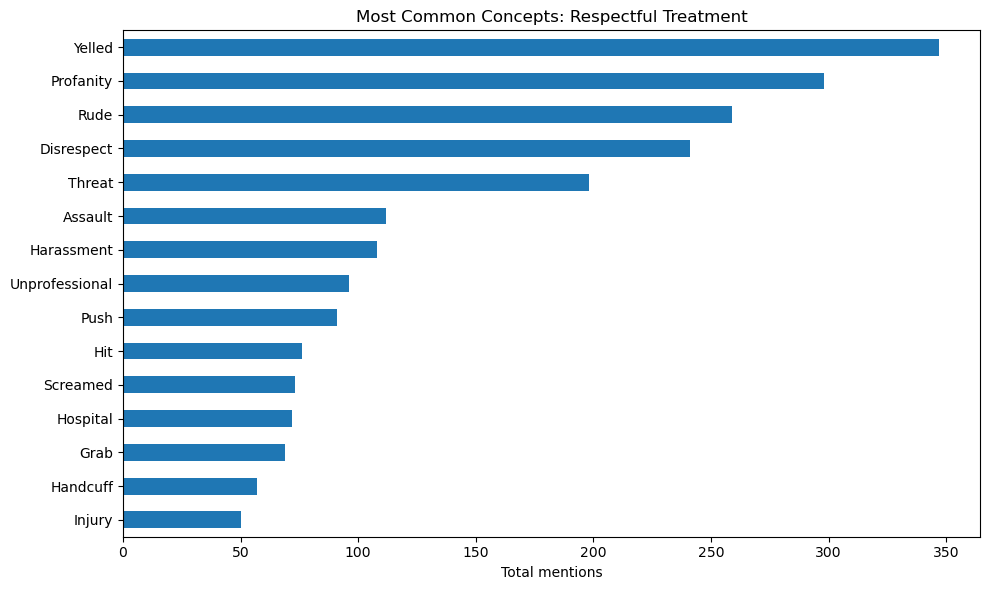

In [28]:
selected_category = df_complaints[CATEGORY_COL].value_counts().index[1]

category_data = df_complaints[df_complaints[CATEGORY_COL] == selected_category]

category_mentions = (
    category_data[list(KEYWORDS)]
    .sum()
    .sort_values(ascending=False)
    .head(15)
    .sort_values()
)

plt.figure(figsize=(10, 6))
category_mentions.plot(kind="barh")

plt.title(f"Most Common Concepts: {selected_category}")
plt.xlabel("Total mentions")
plt.tight_layout()
plt.show()

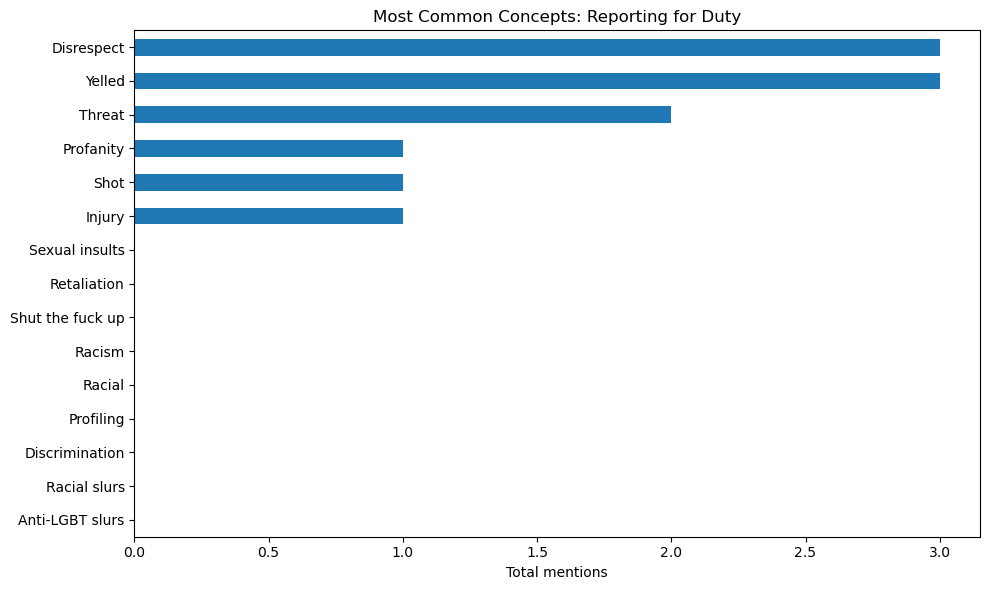

In [29]:
selected_category = df_complaints[CATEGORY_COL].value_counts().index[6]

category_data = df_complaints[df_complaints[CATEGORY_COL] == selected_category]

category_mentions = (
    category_data[list(KEYWORDS)]
    .sum()
    .sort_values(ascending=False)
    .head(15)
    .sort_values()
)

plt.figure(figsize=(10, 6))
category_mentions.plot(kind="barh")

plt.title(f"Most Common Concepts: {selected_category}")
plt.xlabel("Total mentions")
plt.tight_layout()
plt.show()

In [30]:
sorted_categories = df_complaints[CATEGORY_COL].value_counts().sort_values(ascending=False)
print(sorted_categories.head(20))

Neglect of Duty / Unreasonable Judgment    1128
Respectful Treatment                        992
Conduct Unbecoming                          310
Use of Force                                284
Conformance to Laws                         172
Self Identification                         138
Reporting for Duty                          113
Paid Details                                113
Untruthfulness / Inaccurate Reporting        80
Directives / Orders                          73
Alcohol off Duty                             65
Drug Testing / Controlled Substances         57
Abuse of Process                             56
Body-Worn Camera Policy                      47
BIAS-Free Policing Policy                    38
Personal Business                            23
Completion of FIOE Report                    22
Prisoner Handling / Booking Procedures       20
Permissible Weapons & Ammunition             18
CJIS / CORI Access                           18
Name: allegation_clean, dtype: int64


#### Counting proportion of complaints that are Citizen Complaints vs internal Investigation 

In [32]:
df_pov = df_complaints[df_complaints["incident_type_x"] == "Citizen complaint"].count()
df_pov_total = df_complaints.count()
df_pov_percent_cc = (df_pov / df_pov_total) * 100
print(df_pov)
print(df_pov_percent_cc)

ia_no                    3505
incident_type_x          3505
received_date_x          3505
occurred_date_x          2968
allegation_x             3505
                         ... 
Unresponsive             3505
Death                    3505
Touched private parts    3505
Strip search             3505
Threatened to kill       3505
Length: 104, dtype: int64
ia_no                    67.559753
incident_type_x          67.559753
received_date_x          67.559753
occurred_date_x          75.617834
allegation_x             67.559753
                           ...    
Unresponsive             67.559753
Death                    67.559753
Touched private parts    67.559753
Strip search             67.559753
Threatened to kill       67.559753
Length: 104, dtype: float64


In [33]:
count = (df_complaints['incident_type_x'] == "Citizen complaint").sum()
count_total = df_complaints['incident_type_x'].count()
print(f'Total Citizen Complaints: {count}')
print(f'Total Incidents: {count_total}')
print(f'Percentage of Citizen Complaints: {count / count_total * 100:.2f}%')

Total Citizen Complaints: 3505
Total Incidents: 5188
Percentage of Citizen Complaints: 67.56%


In [58]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import normalize

vec = TfidfVectorizer(
    ngram_range=(1, 2),
    min_df=5,        # ignore terms in fewer than 5 complaints
    max_df=0.5,      # ignore terms in over half of complaints (boilerplate)
    stop_words="english",
    sublinear_tf=True,
)
X = vec.fit_transform(df_complaints["narrative_x"])
terms = np.array(vec.get_feature_names_out())

svd = TruncatedSVD(n_components=50, random_state=42)
Z = normalize(svd.fit_transform(X))   # LSA embedding, L2-normalized

In [59]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

scores = {}
for k in range(2, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(Z)
    scores[k] = silhouette_score(Z, km.labels_, metric="cosine")

for k, s in scores.items():
    print(k, round(s, 3))

2 0.065
3 0.089
4 0.103
5 0.117
6 0.124
7 0.136
8 0.108
9 0.157
10 0.154


In [60]:
from sklearn.metrics import adjusted_rand_score

k = 5  # your chosen value
ref = KMeans(n_clusters=k, n_init=10, random_state=0).fit_predict(Z)

aris = []
for seed in range(1, 21):
    labels = KMeans(n_clusters=k, n_init=10, random_state=seed).fit_predict(Z)
    aris.append(adjusted_rand_score(ref, labels))

print("Mean ARI:", round(np.mean(aris), 3), "Min:", round(np.min(aris), 3))

Mean ARI: 0.911 Min: 0.546


In [62]:
df_complaints["cluster"] = KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(Z)

for c in range(k):
    mask = (df_complaints["cluster"] == c).values
    mean_tfidf = np.asarray(X[mask].mean(axis=0)).ravel()
    top = mean_tfidf.argsort()[::-1][:12]
    print(f"Cluster {c} (n={mask.sum()}):", ", ".join(terms[top]))

Cluster 0 (n=414): rule, violation, 102, rule 102, hours, violation rule, tour, worked, duty, id, po, section
Cluster 1 (n=595): complainant, complainant stated, alleges, stated, states, complainant states, complainant alleges, officers, alleged, complainant alleged, arrested, police
Cluster 2 (n=1016): said, car, asked, told, police, did, just, like, officers, time, know, street
Cluster 3 (n=1293): mr, stated, ms, officers, mr stated, sgt, complaint, called, police, told, vehicle, boston
Cluster 4 (n=1870): police, boston, sgt, officers, department, vehicle, incident, det, 11, boston police, court, firearm


In [ ]:
from scipy.stats import chi2_contingency

ct = pd.crosstab(df_complaints["cluster"], df_complaints["allegation_"])
chi2, p, dof, expected = chi2_contingency(ct)

expected = pd.DataFrame(expected, index=ct.index, columns=ct.columns)
std_resid = (ct - expected) / np.sqrt(expected)

print("chi2 =", round(chi2, 2), "p =", p)
print(std_resid.round(2))

# Cramér's V as an effect size
n = ct.values.sum()
cramers_v = np.sqrt(chi2 / (n * (min(ct.shape) - 1)))
print("Cramér's V =", round(cramers_v, 3))

chi2 = 6412.57 p = 1.0978280769426284e-243
allegation_x  & found property  abrahamson bias-free policing policy  \
cluster                                                                
0                        -0.28                                 -0.28   
1                        -0.34                                 -0.34   
2                         1.82                                 -0.44   
3                        -0.50                                 -0.50   
4                        -0.60                                  1.07   

allegation_x  abrahamson conduct unbecoming  \
cluster                                       
0                                     -0.28   
1                                     -0.34   
2                                     -0.44   
3                                     -0.50   
4                                      1.07   

allegation_x  abrahamson neg.duty/unreasonable judge  \
cluster                                                
0         

In [76]:
min_count = 10  # categories with fewer complaints than this go into "Other"
counts = df_complaints["allegation_clean"].value_counts()
keep = counts[counts >= min_count].index

df_complaints["allegation_grouped"] = df_complaints["allegation_clean"].where(df_complaints["allegation_clean"].isin(keep), "Other")
ct = pd.crosstab(df_complaints["cluster"], df_complaints["allegation_grouped"])
print(ct.shape)  # should now be a small number of columns

(5, 31)


In [77]:
chi2, p, dof, expected = chi2_contingency(ct)
print("Cells with expected count < 5:", (expected < 5).sum(), "of", expected.size)

Cells with expected count < 5: 68 of 155


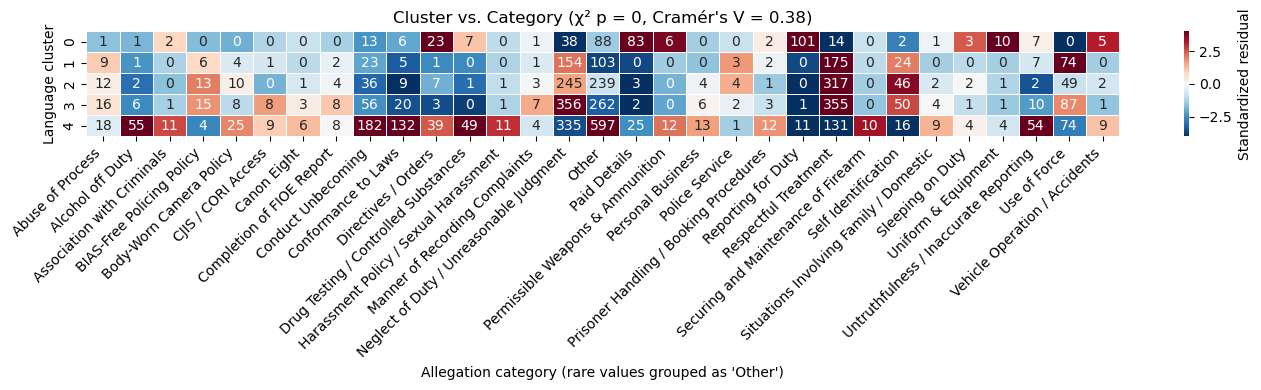

In [78]:
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency

# Build all tables from the same crosstab
ct = pd.crosstab(df_complaints["cluster"], df_complaints["allegation_grouped"])

chi2, p, dof, expected = chi2_contingency(ct)
expected = pd.DataFrame(expected, index=ct.index, columns=ct.columns)
std_resid = (ct - expected) / np.sqrt(expected)

n = ct.values.sum()
cramers_v = np.sqrt(chi2 / (n * (min(ct.shape) - 1)))

# Confirm the shapes match before plotting
assert std_resid.shape == ct.shape, (std_resid.shape, ct.shape)

width = min(14, max(6, 1.2 * ct.shape[1]))
height = min(10, max(4, 0.6 * ct.shape[0]))
fig, ax = plt.subplots(figsize=(width, height))

sns.heatmap(
    std_resid,
    annot=ct.values,   # raw counts as a plain array, so labels line up by position
    fmt="d",
    cmap="RdBu_r",
    center=0,
    vmin=-4, vmax=4,
    linewidths=0.5,
    cbar_kws={"label": "Standardized residual"},
    ax=ax,
)
ax.set_title(f"Cluster vs. Category (χ² p = {p:.3g}, Cramér's V = {cramers_v:.2f})")
ax.set_xlabel("Allegation category (rare values grouped as 'Other')")
ax.set_ylabel("Language cluster")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()